
# Reversible Power Law Modeling of CO₂ Methanation

## Objective

This notebook investigates whether a **physics-based reversible Power Law model** can improve methane-yield prediction compared with a Neural Network, particularly in unseen operating regions and at higher temperatures.

The Power Law describes the reaction rate as a function of temperature, gas partial pressures, and thermodynamic equilibrium. The predicted reaction rate is integrated through a reactor mass balance to calculate the methane yield.

The four kinetic parameters are estimated using **Differential Evolution**, independently on the training data of each validation split:

$$
\theta = (\log k_0, E_A, \alpha, \beta)
$$

## Research Question

**Can a reversible Power Law kinetic model provide more reliable methane-yield predictions than a data-driven Neural Network, especially under unseen operating conditions?**

## Evaluation Strategy

The model is evaluated using the same three validation protocols as the Machine Learning notebook:

1. **Interpolation:** Shuffled 5-fold cross-validation.
2. **Regional generalization:** Leave-One-Cluster-Out validation.
3. **Temperature extrapolation:** Training on temperatures below 260 °C and testing on temperatures at or above 260 °C.

Model performance is evaluated using RMSE, parity plots, and residual analysis. The results are compared with the Neural Network to assess the strengths and limitations of physics-based kinetic modeling.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.integrate import solve_ivp
from scipy.optimize import differential_evolution
from sklearn.cluster import KMeans
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')

ROOT = Path.cwd().parent
DATA_PATH = ROOT / 'data' / 'processed' / 'co2_methanation_clean.csv'
ML_RESULTS_PATH = ROOT / 'reports' / 'baseline_ml' / 'model_comparison.csv'
RESULT_DIR = ROOT / 'reports' / 'physics_based_kinetic_modeling'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

R = 8.314462618                 # J/(mol.K)
PRESSURE_BAR = 3.0              # bar
CATALYST_MASS_KG = 0.000720     # kg
NORMAL_MOLAR_VOLUME_NML_MOL = 22_414.0  # NmL/mol at 0 °C and 1 atm

DE_MAXITER = 200
DE_POPSIZE = 10
PARAMETER_BOUNDS = [
    (-20.0, 40.0),       # log(k0), compatible with the selected units
    (20_000.0, 200_000.0),  # Ea, J/mol
    (-2.0, 4.0),         # alpha
    (-2.0, 4.0),         # beta
]
LARGE_PENALTY = 1e12

## 1. Data preparation

The reported normal volumetric flow is converted from NmL/min to mol/s. `22,414 NmL/mol` means that one mole of ideal gas occupies 22,414 mL under the selected normal reference conditions (0 °C and 1 atm).

In [2]:
df = pd.read_csv(DATA_PATH)

df['temperature_K'] = df['temperature_C'] + 273.15
df['total_flow_mol_s'] = (
    df['flowrate_NmL_min'] / NORMAL_MOLAR_VOLUME_NML_MOL / 60.0
)
df['co2_in_mol_s'] = df['total_flow_mol_s'] * df['CO2_pct'] / 100.0
df['h2_in_mol_s'] = df['total_flow_mol_s'] * df['H2_pct'] / 100.0
df['ar_in_mol_s'] = df['total_flow_mol_s'] * df['Ar_pct'] / 100.0
df['observed_yield_pct'] = df['CH4_yield_pct'].astype(float)

physical_columns = [
    'test_id', 'temperature_K', 'co2_in_mol_s', 'h2_in_mol_s',
    'ar_in_mol_s', 'observed_yield_pct'
]
physical_data = df[physical_columns].copy()
physical_data.head()

,test_id,temperature_K,co2_in_mol_s,h2_in_mol_s,ar_in_mol_s,observed_yield_pct
0,1,513.15,0.000089,0.000356,0.0,11.09
1,2,524.15,0.000089,0.000356,0.0,17.27
2,3,534.15,0.000089,0.000357,0.0,25.56
3,4,545.15,0.000089,0.000356,0.0,34.50
4,5,553.15,0.000089,0.000356,0.0,43.86


In [3]:
physical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
test_id,215.0,108.567442,62.635974,1.000000,54.500000,109.000000,162.500000,216.000000
temperature_K,215.0,521.256977,16.983023,492.150000,504.150000,523.150000,533.150000,574.150000
co2_in_mol_s,215.0,0.000138,0.000095,0.000029,0.000089,0.000095,0.000136,0.000446
h2_in_mol_s,215.0,0.000492,0.000361,0.000047,0.000279,0.000357,0.000535,0.001785
ar_in_mol_s,215.0,0.000074,0.000152,0.000000,0.000000,0.000000,0.000000,0.000526
observed_yield_pct,215.0,11.447163,11.454941,0.150000,5.315000,8.170000,12.935000,71.320000



## 2. Equilibrium Constant

The equilibrium constant describes the thermodynamic equilibrium of the CO₂ methanation reaction as a function of temperature.

The reversible Power Law includes the factor $(1-Q/K_{eq})$, where $Q$ is the reaction quotient calculated from the gas partial pressures.

As the reaction approaches equilibrium, $Q$ approaches $K_{eq}$ and the net reaction rate decreases toward zero.

The equilibrium constant is calculated using the empirical correlation reported in the reference article:

$$
K_{eq}(T)=137T^{-3.998}\exp\left(\frac{158700}{RT}\right)
$$

where $T$ is expressed in Kelvin and $R=8.314$ J/(mol·K).


In [4]:
def equilibrium_constant(temperature_K):
    temperature_K = np.asarray(temperature_K, dtype=float)
    return 137.0 * temperature_K**(-3.998) * np.exp(
        158_700.0 / (R * temperature_K)
    )


## 3. Gas Composition at CO₂ Conversion X

The CO₂ conversion, denoted by $X$, represents the fraction of inlet CO₂ that has been consumed by the reaction.

For the methanation reaction:

$$
CO_2 + 4H_2 \rightleftharpoons CH_4 + 2H_2O
$$

The molar flow rates of CO₂, H₂, CH₄, and H₂O change as the reaction progresses, while the argon flow remains constant because it is an inert gas.

At a given conversion $X$, the molar flow rates are calculated using the reaction stoichiometry.

The partial pressure of each gas is then calculated from its mole fraction and the total reactor pressure:

$$
p_i = P_{\mathrm{total}}\frac{F_i}{F_{\mathrm{total}}}
$$

These partial pressures are used in the reversible Power Law to calculate the reaction rate at each conversion level.

Since the catalyst is assumed to be 100% selective toward methane, the methane yield at the reactor outlet is:

$$
Y_{CH_4}(\%) = 100 X_{\mathrm{out}}
$$


In [5]:
def maximum_conversion(co2_0, h2_0):
    return np.minimum(1.0, h2_0 / (4.0 * co2_0))


def partial_pressures(X, co2_0, h2_0, ar_0):
    X = np.asarray(X, dtype=float)
    co2_0 = np.asarray(co2_0, dtype=float)
    h2_0 = np.asarray(h2_0, dtype=float)
    ar_0 = np.asarray(ar_0, dtype=float)

    co2 = co2_0 * (1.0 - X)
    h2 = h2_0 - 4.0 * co2_0 * X
    ch4 = co2_0 * X
    h2o = 2.0 * co2_0 * X
    ar = ar_0
    flows = np.stack(np.broadcast_arrays(co2, h2, ch4, h2o, ar), axis=0)

    if np.any(flows < -1e-12):
        raise ValueError('Conversion produces a negative molar flow')
    flows = np.maximum(flows, 0.0)
    total = flows.sum(axis=0)
    if np.any(total <= 0):
        raise ValueError('Total molar flow must remain positive')

    pressures = PRESSURE_BAR * flows / total
    return {
        name: value for name, value in zip(
            ['CO2', 'H2', 'CH4', 'H2O', 'Ar'], pressures
        )
    }


## 4. Reversible Power Law Reaction Rate

The reversible Power Law model calculates the net CO₂ methanation reaction rate as a function of temperature, gas partial pressures, and thermodynamic equilibrium.

The kinetic expression is:

$$
r=\exp\left(\log k_0-\frac{E_A}{RT}\right)
p_{CO_2}^{\alpha}p_{H_2}^{\beta}
\left(1-\frac{Q}{K_{eq}}\right)
$$

where the reaction quotient is:

$$
Q=\frac{p_{H_2O}^{2}p_{CH_4}}
{p_{H_2}^{4}p_{CO_2}}
$$

The reaction rate is determined by three contributions:

- **Temperature dependence:** The Arrhenius equation describes how the kinetic constant changes with temperature.
- **Reactant partial pressures:** The reaction orders describe the sensitivity of the rate to CO₂ and H₂.
- **Thermodynamic equilibrium:** The reversible term reduces the net reaction rate as the gas composition approaches equilibrium.

The four kinetic parameters $(\log k_0,E_A,\alpha,\beta)$ will be estimated using Differential Evolution.

Small numerical safeguards are introduced to avoid divisions by zero and invalid fractional powers near reactant depletion. Physical conversion limits and equilibrium behavior must also be respected during reactor integration.

The function returns the net reaction rate in mol/(kg-catalyst·s), which is subsequently used in the reactor mass balance to calculate methane yield.


In [6]:
def power_law_rate(X, experiment, params):
    log_k0, activation_energy, alpha, beta = params
    pressures = partial_pressures(
        X, experiment['co2_0'], experiment['h2_0'], experiment['ar_0']
    )
    eps = 1e-14
    p_co2 = np.maximum(pressures['CO2'], eps)
    p_h2 = np.maximum(pressures['H2'], eps)
    p_ch4 = np.maximum(pressures['CH4'], 0.0)
    p_h2o = np.maximum(pressures['H2O'], 0.0)

    kinetic_constant = np.exp(
        log_k0 - activation_energy / (R * experiment['temperature_K'])
    )
    reaction_quotient = p_h2o**2 * p_ch4 / (p_h2**4 * p_co2)
    driving_force = 1.0 - reaction_quotient / equilibrium_constant(
        experiment['temperature_K']
    )
    rate = kinetic_constant * p_co2**alpha * p_h2**beta * driving_force
    return np.maximum(rate, 0.0)


## 5. Reactor Model and Methane Yield Prediction

The reversible Power Law calculates the local reaction rate, but our objective is to predict the **methane yield at the reactor outlet**.

To connect the reaction rate to methane yield, we model the reactor as an **isothermal plug-flow fixed-bed reactor**, using the catalyst mass $W$ as the integration coordinate.

### Reactor Mass Balance

The CO₂ conversion evolves along the catalyst bed according to:

$$
\frac{dX}{dW}=\frac{r(X)}{F_{CO_2,0}}
$$

where:

- $X$ is the CO₂ conversion (fraction between 0 and 1).
- $W$ is the cumulative catalyst mass (kg).
- $r(X)$ is the net reaction rate predicted by the reversible Power Law (mol/kg_cat/s).
- $F_{CO_2,0}$ is the inlet CO₂ molar flow rate (mol/s).

At the reactor inlet, the initial conversion is zero:

$$
X(W=0)=0
$$

The equation is numerically integrated over the total catalyst mass:

$$
W \in [0,\ 0.000720]\ \mathrm{kg}
$$

Assuming 100% selectivity toward methane, the predicted methane yield is:

$$
\boxed{Y_{CH_4,\mathrm{pred}}(\%)=100X_{\mathrm{out}}}
$$

### Numerical Implementation

The `predict_yields()` function uses `scipy.integrate.solve_ivp` to solve the reactor mass balance for multiple experiments simultaneously.

Each experiment has its own temperature, inlet gas composition, and molar flow rates, while all experiments share the same kinetic parameters:

$$
\theta=(\log k_0,E_A,\alpha,\beta)
$$

During integration, the gas partial pressures and reaction rates are continuously updated as the CO₂ conversion changes.

The function also applies numerical safeguards to respect stoichiometric conversion limits and avoid invalid calculations near reactant depletion.

It returns an array of predicted methane yields, expressed in percentages, which will be compared with experimental measurements during parameter optimization using Differential Evolution.


In [7]:
def predict_yields(row_indices, params):
    selected = physical_data.iloc[np.asarray(row_indices)]
    temperature = selected['temperature_K'].to_numpy()
    co2_0 = selected['co2_in_mol_s'].to_numpy()
    h2_0 = selected['h2_in_mol_s'].to_numpy()
    ar_0 = selected['ar_in_mol_s'].to_numpy()
    limits = maximum_conversion(co2_0, h2_0)
    batch_experiment = {
        'temperature_K': temperature,
        'co2_0': co2_0,
        'h2_0': h2_0,
        'ar_0': ar_0,
    }

    def ode(_, conversion):
        safe_conversion = np.minimum(conversion, limits * (1.0 - 1e-10))
        rate = power_law_rate(safe_conversion, batch_experiment, params)
        derivative = rate / co2_0
        return np.where(conversion >= limits * (1.0 - 1e-8), 0.0, derivative)

    solution = solve_ivp(
        ode, (0.0, CATALYST_MASS_KG), np.zeros(len(selected)),
        rtol=2e-6, atol=1e-9, max_step=CATALYST_MASS_KG / 20.0,
    )
    if not solution.success or solution.t[-1] < CATALYST_MASS_KG - 1e-12:
        raise RuntimeError(f'Batch reactor integration failed: {solution.message}')
    predictions = 100.0 * np.clip(solution.y[:, -1], 0.0, limits)
    if not np.all(np.isfinite(predictions)):
        raise RuntimeError('Non-finite reactor prediction')
    return predictions

## 6. Parameter optimization with Differential Evolution

The optimizer minimizes training MSE. RMSE is reserved for reporting; minimizing MSE or RMSE produces the same optimum because the square root is monotonic.

Invalid numerical solutions receive a large penalty. No experimental test yield is used during optimization.

In [8]:
def objective(params, train_indices):
    try:
        predictions = predict_yields(train_indices, params)
    except (RuntimeError, ValueError, FloatingPointError, OverflowError):
        return LARGE_PENALTY
    observations = physical_data.iloc[np.asarray(train_indices)][
        'observed_yield_pct'
    ].to_numpy()
    rmse = root_mean_squared_error(observations, predictions)
    return float(rmse) if np.isfinite(rmse) else LARGE_PENALTY


def optimize_power_law(train_indices, seed=RANDOM_STATE):
    result = differential_evolution(
        objective,
        bounds=PARAMETER_BOUNDS,
        args=(np.asarray(train_indices),),
        seed=seed,
        maxiter=DE_MAXITER,
        popsize=DE_POPSIZE,
        polish=True,
        tol=1e-6,
        atol=1e-8,
        workers=1,
        updating='immediate',
    )
    if not np.isfinite(result.fun) or result.fun >= LARGE_PENALTY:
        raise RuntimeError(f'Differential Evolution failed: {result.message}')
    return result

## 7. Validation protocols

Differential Evolution is rerun independently inside every training split. This avoids leakage: the excluded observations never influence the fitted kinetic parameters.

In [9]:
interpolation_splits = list(
    KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(df)
)

clustering_features = [
    'temperature_C', 'GHSV_h-1', 'H2_CO2_ratio', 'Ar_pct'
]
scaled_clustering_data = StandardScaler().fit_transform(df[clustering_features])
cluster_labels = KMeans(
    n_clusters=5, n_init=20, random_state=RANDOM_STATE
).fit_predict(scaled_clustering_data)
region_splits = [
    (np.flatnonzero(cluster_labels != cluster),
     np.flatnonzero(cluster_labels == cluster))
    for cluster in sorted(np.unique(cluster_labels))
]

extrapolation_splits = [(
    np.flatnonzero(df['temperature_C'].to_numpy() < 260.0),
    np.flatnonzero(df['temperature_C'].to_numpy() >= 260.0),
)]

cluster_profile = (
    df.assign(cluster=cluster_labels)
    .groupby('cluster')
    .agg(
        n=('test_id', 'size'),
        temperature_min=('temperature_C', 'min'),
        temperature_max=('temperature_C', 'max'),
        yield_mean=('CH4_yield_pct', 'mean'),
    )
)

In [10]:
def evaluate_protocol(protocol, splits):
    metric_rows = []
    prediction_frames = []

    for split_id, (train_indices, test_indices) in enumerate(splits):
        print(f'{protocol}: fitting split {split_id + 1}/{len(splits)}')
        fit = optimize_power_law(train_indices, seed=RANDOM_STATE)
        predicted = predict_yields(test_indices, fit.x)
        observed = physical_data.iloc[test_indices]['observed_yield_pct'].to_numpy()

        metric_rows.append({
            'protocol': protocol,
            'split': split_id,
            'n_train': len(train_indices),
            'n_test': len(test_indices),
            'RMSE': root_mean_squared_error(observed, predicted),
            'log_k0': fit.x[0],
            'k0': np.exp(fit.x[0]),
            'Ea_kJ_mol': fit.x[1] / 1000.0,
            'alpha_CO2': fit.x[2],
            'beta_H2': fit.x[3],
            'optimizer_success': fit.success,
            'optimizer_message': fit.message,
            'iterations': fit.nit,
            'function_evaluations': fit.nfev,
        })
        prediction_frames.append(pd.DataFrame({
            'protocol': protocol,
            'split': split_id,
            'row_index': test_indices,
            'test_id': df.iloc[test_indices]['test_id'].to_numpy(),
            'temperature_C': df.iloc[test_indices]['temperature_C'].to_numpy(),
            'observed': observed,
            'predicted': predicted,
            'residual': predicted - observed,
        }))

    return pd.DataFrame(metric_rows), pd.concat(prediction_frames, ignore_index=True)


protocol_splits = {
    'interpolation': interpolation_splits,
    'region_generalization': region_splits,
    'temperature_extrapolation': extrapolation_splits,
}
evaluation_results = {
    protocol: evaluate_protocol(protocol, splits)
    for protocol, splits in protocol_splits.items()
}
metrics = pd.concat(
    [result[0] for result in evaluation_results.values()], ignore_index=True
)
predictions = pd.concat(
    [result[1] for result in evaluation_results.values()], ignore_index=True
)

interpolation: fitting split 1/5
interpolation: fitting split 2/5
interpolation: fitting split 3/5
interpolation: fitting split 4/5
interpolation: fitting split 5/5
region_generalization: fitting split 1/5
region_generalization: fitting split 2/5
region_generalization: fitting split 3/5
region_generalization: fitting split 4/5
region_generalization: fitting split 5/5
temperature_extrapolation: fitting split 1/1


In [18]:
summary = (
    metrics.groupby('protocol', as_index=False)
    .agg(
        RMSE_mean=('RMSE', 'mean'),
        RMSE_std=('RMSE', 'std'),
        n_splits=('RMSE', 'count'),
    )
)

summary['RMSE_std'] = summary['RMSE_std'].fillna(0)

summary.round(3)

,protocol,RMSE_mean,RMSE_std,n_splits
0,interpolation,1.628,0.167,5
1,region_generalization,2.680,2.222,5
2,temperature_extrapolation,3.607,0.000,1


## 8. Results and diagnostic plots

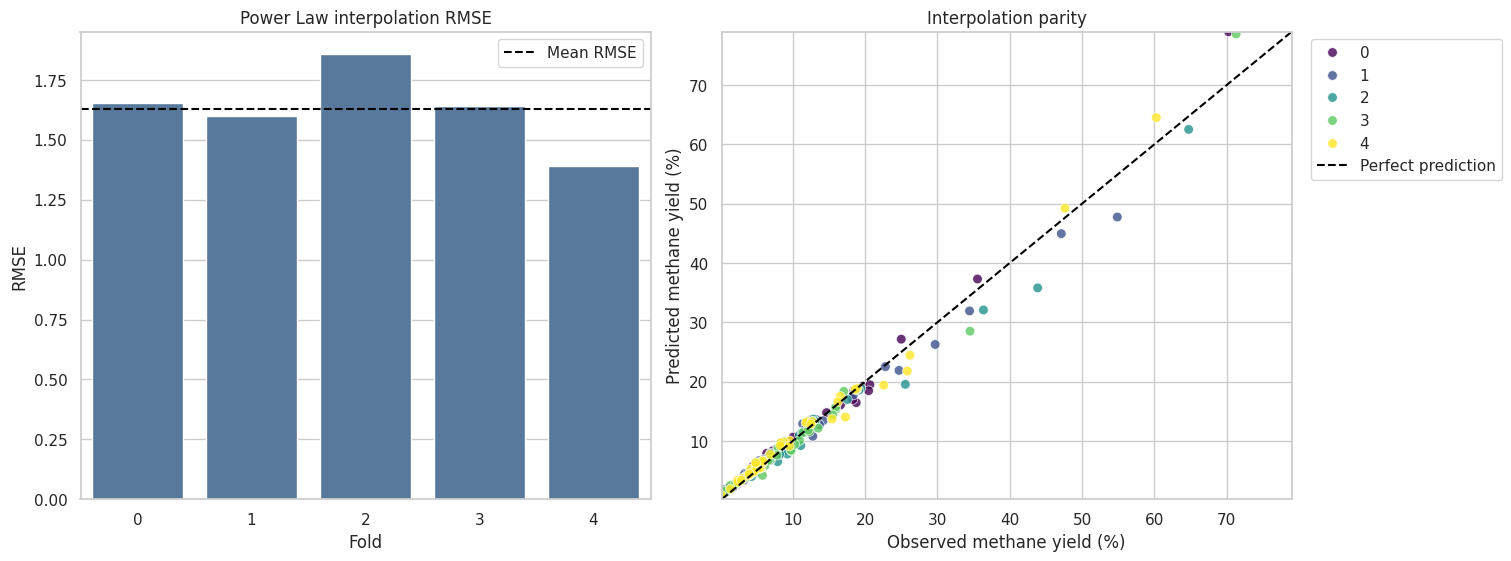

In [19]:
def parity_limits(frame):
    low = min(frame['observed'].min(), frame['predicted'].min())
    high = max(frame['observed'].max(), frame['predicted'].max())
    return [low, high]


fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
interpolation_metrics = metrics[metrics['protocol'] == 'interpolation']
sns.barplot(
    data=interpolation_metrics, x='split', y='RMSE',
    color='#4C78A8', ax=axes[0]
)
axes[0].axhline(
    interpolation_metrics['RMSE'].mean(), color='black', linestyle='--',
    label='Mean RMSE'
)
axes[0].set(title='Power Law interpolation RMSE', xlabel='Fold', ylabel='RMSE')
axes[0].legend()

interpolation_predictions = predictions[
    predictions['protocol'] == 'interpolation'
]
limits = parity_limits(interpolation_predictions)
sns.scatterplot(
    data=interpolation_predictions, x='observed', y='predicted',
    hue='split', palette='viridis', s=48, alpha=0.8, ax=axes[1]
)
axes[1].plot(limits, limits, '--', color='black', label='Perfect prediction')
axes[1].set(
    xlim=limits, ylim=limits, title='Interpolation parity',
    xlabel='Observed methane yield (%)', ylabel='Predicted methane yield (%)'
)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(RESULT_DIR / 'interpolation.png', dpi=180, bbox_inches='tight')
plt.show()

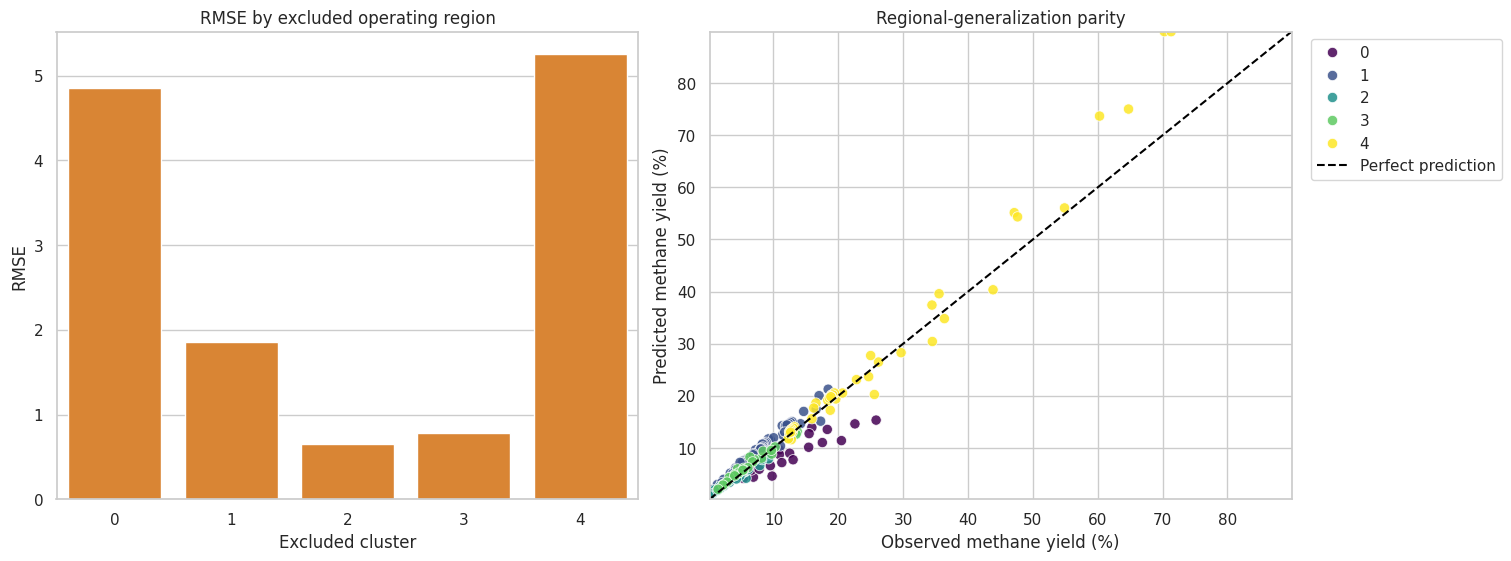

In [20]:
region_metrics = metrics[metrics['protocol'] == 'region_generalization']
region_predictions = predictions[predictions['protocol'] == 'region_generalization']
limits = parity_limits(region_predictions)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
sns.barplot(data=region_metrics, x='split', y='RMSE', color='#F58518', ax=axes[0])
axes[0].set(
    title='RMSE by excluded operating region',
    xlabel='Excluded cluster', ylabel='RMSE'
)
sns.scatterplot(
    data=region_predictions, x='observed', y='predicted', hue='split',
    palette='viridis', s=55, alpha=0.85, ax=axes[1]
)
axes[1].plot(limits, limits, '--', color='black', label='Perfect prediction')
axes[1].set(
    xlim=limits, ylim=limits, title='Regional-generalization parity',
    xlabel='Observed methane yield (%)', ylabel='Predicted methane yield (%)'
)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(RESULT_DIR / 'regional_generalization.png', dpi=180, bbox_inches='tight')
plt.show()

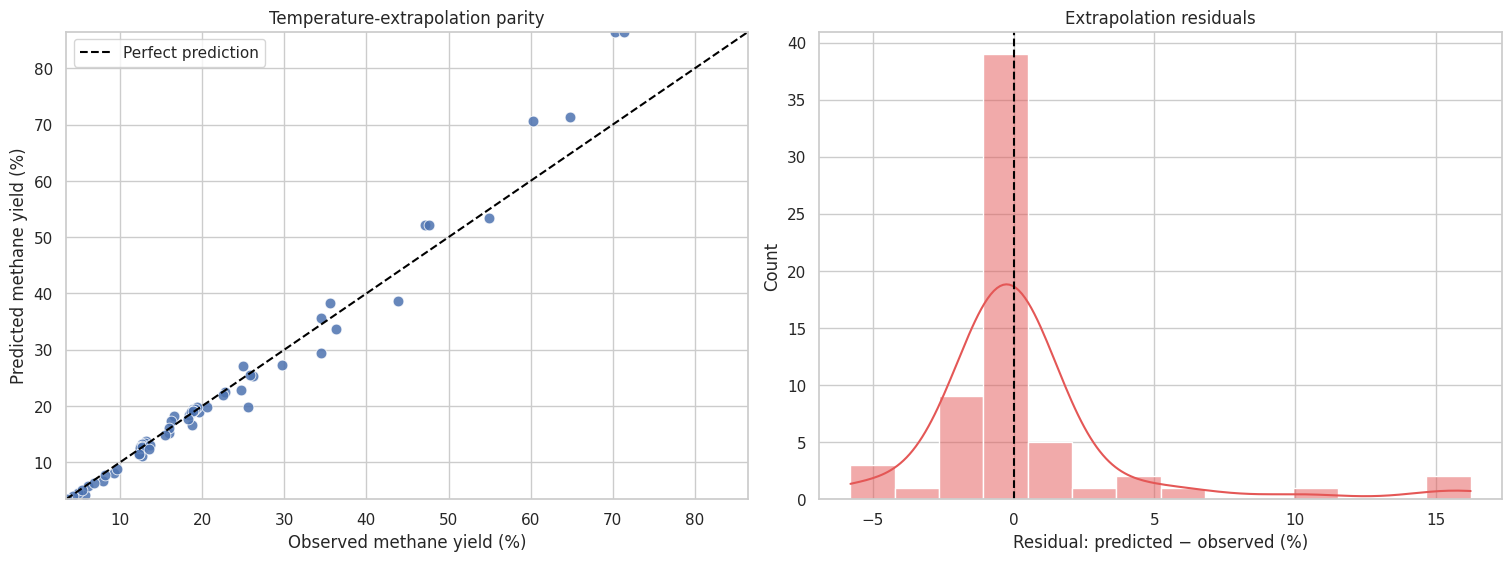

In [21]:
extrapolation_predictions = predictions[
    predictions['protocol'] == 'temperature_extrapolation'
]
limits = parity_limits(extrapolation_predictions)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
sns.scatterplot(
    data=extrapolation_predictions, x='observed', y='predicted',
    s=60, alpha=0.85, ax=axes[0]
)
axes[0].plot(limits, limits, '--', color='black', label='Perfect prediction')
axes[0].set(
    xlim=limits, ylim=limits, title='Temperature-extrapolation parity',
    xlabel='Observed methane yield (%)', ylabel='Predicted methane yield (%)'
)
axes[0].legend()
sns.histplot(
    data=extrapolation_predictions, x='residual', bins=14,
    color='#E45756', kde=True, ax=axes[1]
)
axes[1].axvline(0.0, color='black', linestyle='--')
axes[1].set(
    title='Extrapolation residuals',
    xlabel='Residual: predicted − observed (%)', ylabel='Count'
)
fig.savefig(RESULT_DIR / 'temperature_extrapolation.png', dpi=180, bbox_inches='tight')
plt.show()

## 9. Comparison with the Neural Network

The Neural Network values are loaded from the baseline notebook output.

In [22]:
ml_results = pd.read_csv(ML_RESULTS_PATH)
neural_network = ml_results.loc[ml_results['model'] == 'Neural Network'].iloc[0]
power_law_scores = summary.set_index('protocol')['RMSE_mean']

comparison = pd.DataFrame({
    'Scenario': ['Interpolation', 'Regional generalization', 'Temperature extrapolation'],
    'Neural Network': [
        neural_network['interpolation_RMSE'],
        neural_network['region_RMSE'],
        neural_network['extrapolation_RMSE'],
    ],
    'Reversible Power Law': [
        power_law_scores['interpolation'],
        power_law_scores['region_generalization'],
        power_law_scores['temperature_extrapolation'],
    ],
})
comparison['Power Law improvement (%)'] = 100.0 * (
    comparison['Neural Network'] - comparison['Reversible Power Law']
) / comparison['Neural Network']
comparison

,Scenario,Neural Network,Reversible Power Law,Power Law improvement (%)
0,Interpolation,1.753856,1.628294,7.159224
1,Regional generalization,6.264348,2.680394,57.211927
2,Temperature extrapolation,10.416694,3.607421,65.368849


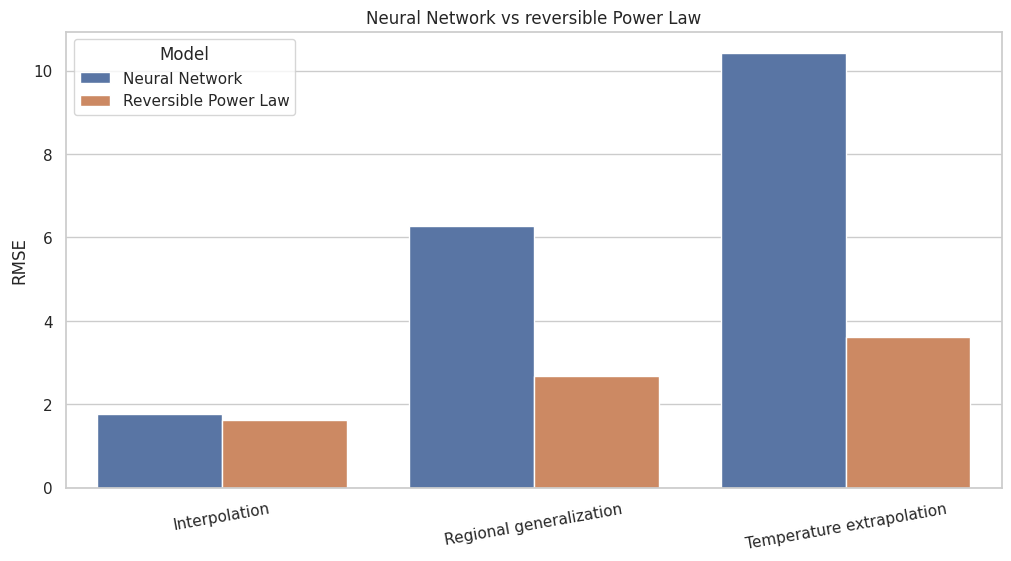

In [23]:
comparison_long = comparison.melt(
    id_vars='Scenario',
    value_vars=['Neural Network', 'Reversible Power Law'],
    var_name='Model', value_name='RMSE'
)
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
sns.barplot(data=comparison_long, x='Scenario', y='RMSE', hue='Model', ax=ax)
ax.set(title='Neural Network vs reversible Power Law', xlabel='', ylabel='RMSE')
ax.tick_params(axis='x', rotation=10)
fig.savefig(RESULT_DIR / 'model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

metrics.to_csv(RESULT_DIR / 'power_law_metrics.csv', index=False)
comparison.to_csv(RESULT_DIR / 'model_comparison.csv', index=False)

## Conclusion

The results support the research hypothesis:

> The reversible Power Law provides similar interpolation accuracy but considerably better regional generalization and temperature extrapolation than the Neural Network.

The Neural Network learns correlations represented in the training data. When the operating distribution changes, its performance deteriorates. The Power Law uses a physically meaningful temperature dependence, reaction stoichiometry, material balance and equilibrium limitation. These constraints allow it to behave more realistically outside the training domain.

Nevertheless, the Power Law is not perfect. Clusters 0 and 4 remain difficult, and several high-temperature observations are overpredicted. The model’s four-parameter structure may not fully represent adsorption, catalyst-surface effects or inhibition by products.

The Langmuir−Hinshelwood-Hougen-Watson (LHHW) model is the logical next kinetic model because it can represent adsorption and surface-reaction effects that the simple Power Law cannot